# RF versus RFSI: why does validation strategy matter?
## A spatial modelling experiment with Meuse zinc (in Python)
**Olha Kachalova**

Historical mining and industrial activity upstream contaminated the Meuse River sediments with heavy metals. Repeated flooding deposited these sediments across the floodplain. Our task is to predict zinc concentration at unsampled locations.

### Research questions
1. Is RFSI more accurate than ordinary Random Forest (RF)? Does adding environmental predictors change the result?
2. Do different validation strategies lead to different accuracy estimates and model rankings?
3. Does the appropriate validation strategy depend on the sampling design?

### Main references
- Sekulić et al. (2020), [Random Forest Spatial Interpolation](https://doi.org/10.3390/rs12101687).
- Linnenbrink et al. (2024), [kNNDM cross-validation](https://doi.org/10.5194/gmd-17-5897-2024).
- `sp` documentation: [Meuse observations](https://edzer.github.io/sp/reference/meuse.html) and [prediction grid](https://edzer.github.io/sp/reference/meuse.grid.html).

### Run this notebook

- **Google Colab:** upload this `.ipynb` at [colab.research.google.com](https://colab.research.google.com/) (or open it from the GitHub tab), choose a standard CPU runtime, then select **Runtime → Run all**.
- **Local Jupyter:** use a fresh Python 3.10–3.13 environment. Install the packages in the setup section below (or use `python -m pip install -r requirements.txt` if you downloaded the repository). Open the notebook and select **Kernel → Restart Kernel and Run All Cells**.

The first run needs an internet connection to install missing packages and download the Meuse data. Data are cached in `data/` for subsequent local runs. All illustrations are contained in the notebook, and saved analytical outputs are included so the notebook can also be read without executing it. The displayed analytical results come from the author's saved Meuse run; rerunning recomputes them. Small differences can occur across package versions. No GPU, R installation or GIS software is required.


## 1. Some theory: RF versus RFSI

Let $z(s)$ be zinc concentration and $c(s)$ the environmental
predictors at location $s$.

**RF** uses only environmental predictors:

$$\hat z(s_0)=f_{RF}\{c(s_0)\}.$$

**RFSI** additionally uses the measured zinc values and
distances of the five nearest neighbours:

$$\hat z(s_0)=f_{RF}\{c(s_0),z(s_{(1)}),\ldots,z(s_{(5)}),d_{(1)},\ldots,d_{(5)}\}.$$

The RF algorithm is the same in both cases; only the input
features differ. RFSI learns how to combine neighbouring
observations with environmental information.

We do not include coordinates `x`, `y` as direct predictors
in either model.

The RF/RFSI schematic is displayed just after the software setup.

## 2. Setting up the software

Run the next cell once in a fresh Python kernel. It installs only missing core libraries (and the optional `.rda` reader, if needed). In a managed environment where package installation is restricted, install the libraries manually first. An internet connection is required when installing packages.

All experiments use the same RF parameters and five neighbours for RFSI. The CPU settings keep resource use modest. A fresh, consistently installed Python environment is preferable to mixing pip and Conda binary packages in an existing GIS environment.

`N_TREES = 600` reproduces the experiment. For a quick classroom trial you can lower it, but the accuracy values may then differ from the saved results.

If a warning about incompatible Intel and LLVM OpenMP libraries appears, use a fresh environment; limiting threads does not eliminate that library conflict.

In [1]:
# Install missing dependencies in the current notebook kernel (local Jupyter or Colab).
import os
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

warnings.filterwarnings(
    "ignore",
    message=r"(?s).*Found Intel OpenMP.*LLVM OpenMP.*",
    category=RuntimeWarning
)

import sys
import importlib.util
import importlib.metadata as metadata
import subprocess
from pathlib import Path

# Limit native numerical threads before importing NumPy / SciPy / scikit-learn.
# This is not a fix for an environment containing incompatible OpenMP runtimes.
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[variable] = "1"

packages = {
    "numpy": "numpy>=1.24", "pandas": "pandas>=1.5",
    "scipy": "scipy>=1.10", "sklearn": "scikit-learn>=1.2",
    "matplotlib": "matplotlib>=3.6", "seaborn": "seaborn>=0.12",
}
missing = [spec for module, spec in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

DATA_DIR = Path("data")
# pyreadr is used for the original R data. CSV copies are also supported.
if (not all((DATA_DIR / f"{name}.csv").is_file()
            for name in ("meuse", "meuse.grid"))
        and importlib.util.find_spec("pyreadr") is None):
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "pyreadr>=0.5"])
    except (subprocess.CalledProcessError, OSError):
        print("Optional pyreadr installation failed; the data cell will try CSV downloads.")

from urllib.request import urlopen, Request
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, cut_tree
from scipy.stats import ks_2samp, wasserstein_distance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Static figures, compatible with standard notebook viewers.
%matplotlib inline

RANDOM_STATE = 2026
N_SPLITS = 5
N_TREES = 600
K_NEIGHBORS = 5
METHODS = ["RF", "RFSI"]
CV_ORDER = ["Random CV", "Spatial CV", "kNNDM CV"]
CAT = ["ffreq", "soil"]

sns.set_theme(style="whitegrid")
for package in ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn"):
    print(f"{package}: {metadata.version(package)}")


numpy: 2.4.2
pandas: 3.0.0
scipy: 1.17.0
scikit-learn: 1.8.0
matplotlib: 3.10.8
seaborn: 0.13.2


**Figure 1.** RF versus RFSI: environmental predictors and spatial neighbours. Three neighbours are shown for illustration; the modelling experiment uses five nearest observations and their distances.

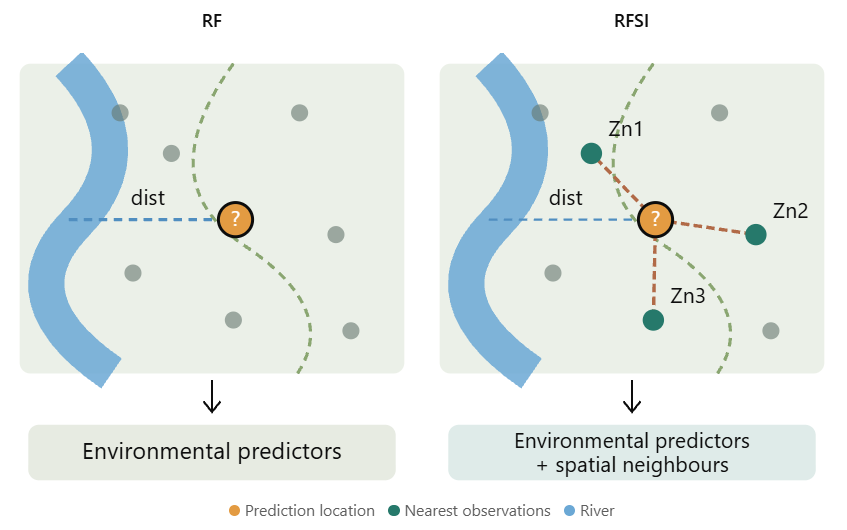

In [2]:
#@title RF versus RFSI illustration { display-mode: "form" }
# Original figure embedded as PNG; no external image file is needed.
from base64 import b64decode
from IPython.display import Image, display

display(Image(data=b64decode(
    "..."
), format="png", width=847))


## 3. Meuse dataset

The dataset contains 155 topsoil observations from the Meuse floodplain near Stein, the Netherlands, and a prediction grid of 3,103 cells (40 m resolution). Zinc is measured in mg kg$^{-1}$. Coordinates are in RD New (EPSG:28992), so distances between locations are in metres.

| Variable | Meaning |
|---|---|
| `zinc` | Target variable: zinc concentration |
| `dist` | Normalized distance to the river (0–1) |
| `ffreq` | Flood-frequency class: 1 = every 2 years, 2 = every 10 years, 3 = every 50 years |
| `soil` | Mapped soil type (three classes) |

The flood-frequency grid has an uncertain origin, and mapped soil classes should also be interpreted cautiously (see dataset documentation).

*Meuse study area: orthophoto with sampling locations (red points), study-area boundary (red outline) and river (blue line). 

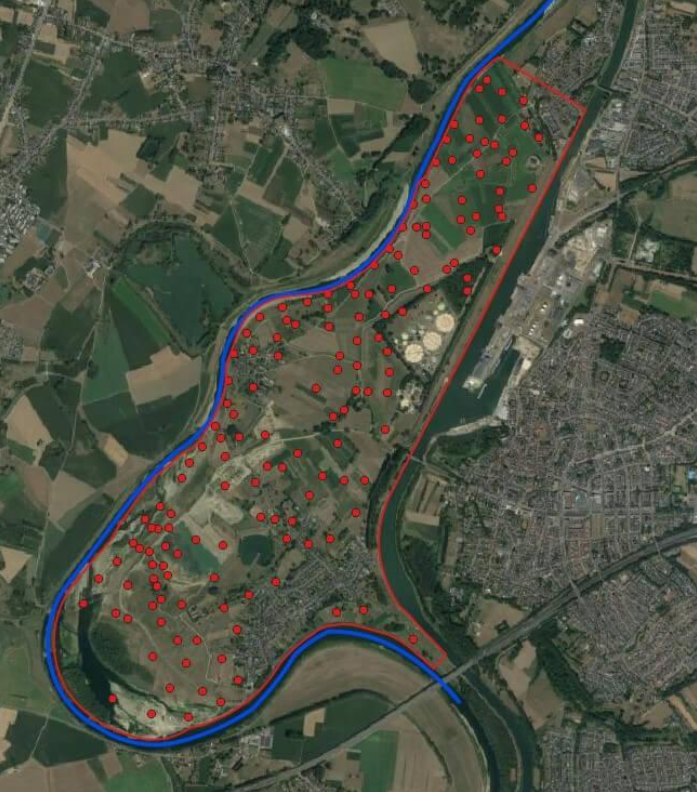

In [3]:
#@title Embedded Meuse orthophoto { display-mode: "form" }
# Original orthophoto embedded as PNG; no external file is needed.
from base64 import b64decode
from IPython.display import Image, display

display(Image(data=b64decode(
    "..."
), format="png", width=590))


In [4]:
DATA_DIR.mkdir(exist_ok=True)
RDA_BASES = [
    "https://raw.githubusercontent.com/edzer/sp/master/data",
    "https://raw.githubusercontent.com/cran/sp/master/data",
]
# CSV copies used in UC Davis's spatial-statistics teaching materials.
CSV_BASE = "https://raw.githubusercontent.com/ucdavisdatalab/workshop-spatial-stats/master/data"


def download_file(url, destination):
    # Write atomically so an interrupted download cannot leave a broken cache.
    temporary = destination.with_suffix(destination.suffix + ".part")
    try:
        request = Request(url, headers={"User-Agent": "Meuse-teaching-notebook/1.0"})
        with urlopen(request, timeout=45) as response, temporary.open("wb") as out:
            shutil.copyfileobj(response, out)
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)


def check_data(df, name):
    required = {"x", "y", "dist", "soil", "ffreq"}
    expected = 3103
    if name == "meuse":
        required.add("zinc")
        expected = 155
    if len(df) != expected or not required.issubset(df.columns):
        raise ValueError(f"Unexpected shape or missing columns in {name}: {df.shape}")
    return df.reset_index(drop=True)


def load_meuse(name):
    csv = DATA_DIR / f"{name}.csv"
    rda = DATA_DIR / f"{name}.rda"
    errors = []
    # Allow an offline copy of the original data in CSV form.
    if csv.is_file():
        try:
            df = check_data(pd.read_csv(csv), name)
            print(f"Loaded {csv}")
            return df
        except Exception as exc:
            errors.append(f"{csv}: {exc}")

    try:
        import pyreadr
    except ImportError as exc:
        errors.append(f"pyreadr: {exc}")
    else:
        if rda.is_file():
            try:
                df = check_data(pyreadr.read_r(str(rda))[name], name)
                print(f"Loaded {rda}")
                return df
            except Exception as exc:
                errors.append(f"{rda}: {exc}")
        for base in RDA_BASES:
            url = f"{base}/{name}.rda"
            try:
                download_file(url, rda)
                df = check_data(pyreadr.read_r(str(rda))[name], name)
                print(f"Downloaded {url}")
                return df
            except Exception as exc:
                errors.append(f"{url}: {exc}")

    url = f"{CSV_BASE}/{name}.csv"
    try:
        download_file(url, csv)
        df = check_data(pd.read_csv(csv), name)
        print(f"Downloaded {url} (CSV mirror)")
        return df
    except Exception as exc:
        errors.append(f"{url}: {exc}")

    raise RuntimeError(
        f"Could not load {name}. Check your internet connection, or place "
        f"the original {name}.rda or {name}.csv in {DATA_DIR.resolve()}.\n"
        + "\n".join(errors)
    )


meuse = load_meuse("meuse")
grid = load_meuse("meuse.grid")

# Treat flood and soil classes as categories, not numerical scales.
for df in (meuse, grid):
    for col in CAT:
        df[col] = (df[col].astype("string").str.strip()
                   .str.replace(r"\.0$", "", regex=True)
                   .replace(["Missing", "nan", "None", "NA", ""], pd.NA))
    for col in ["x", "y", "dist"]:
        df[col] = pd.to_numeric(df[col], errors="raise")
meuse["zinc"] = pd.to_numeric(meuse["zinc"], errors="raise")

print("Observations:", meuse.shape)
print("Prediction grid:", grid.shape)
display(meuse.head())


Loaded data\meuse.rda
Loaded data\meuse.grid.rda
Observations: (155, 14)
Prediction grid: (3103, 7)


,x,y,cadmium,copper,lead,zinc,elev,dist,om,ffreq,soil,lime,landuse,dist.m
0,181072.0,333611.0,11.7,85.0,299.0,1022.0,7.909,0.001358,13.6,1,1,1,Ah,50.0
1,181025.0,333558.0,8.6,81.0,277.0,1141.0,6.983,0.012224,14.0,1,1,1,Ah,30.0
2,181165.0,333537.0,6.5,68.0,199.0,640.0,7.800,0.103029,13.0,1,1,1,Ah,150.0
3,181298.0,333484.0,2.6,81.0,116.0,257.0,7.655,0.190094,8.0,1,2,0,Ga,270.0
4,181307.0,333330.0,2.8,48.0,117.0,269.0,7.480,0.277090,8.7,1,2,0,Ah,380.0


### Data integrity and exploratory analysis

Before modelling, let's check missing values, duplicate coordinates, numerical ranges and the representation of environmental classes at observations and prediction locations.

Observations — missing values:


,x,y,dist,ffreq,soil,zinc
Missing,0,0,0,0,0,0


Prediction grid — missing values:


,x,y,dist,ffreq,soil
Missing,0,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
zinc,155.0,469.72,367.07,113.0,198.00,326.00,674.50,1839.00
dist,155.0,0.24,0.20,0.0,0.08,0.21,0.36,0.88


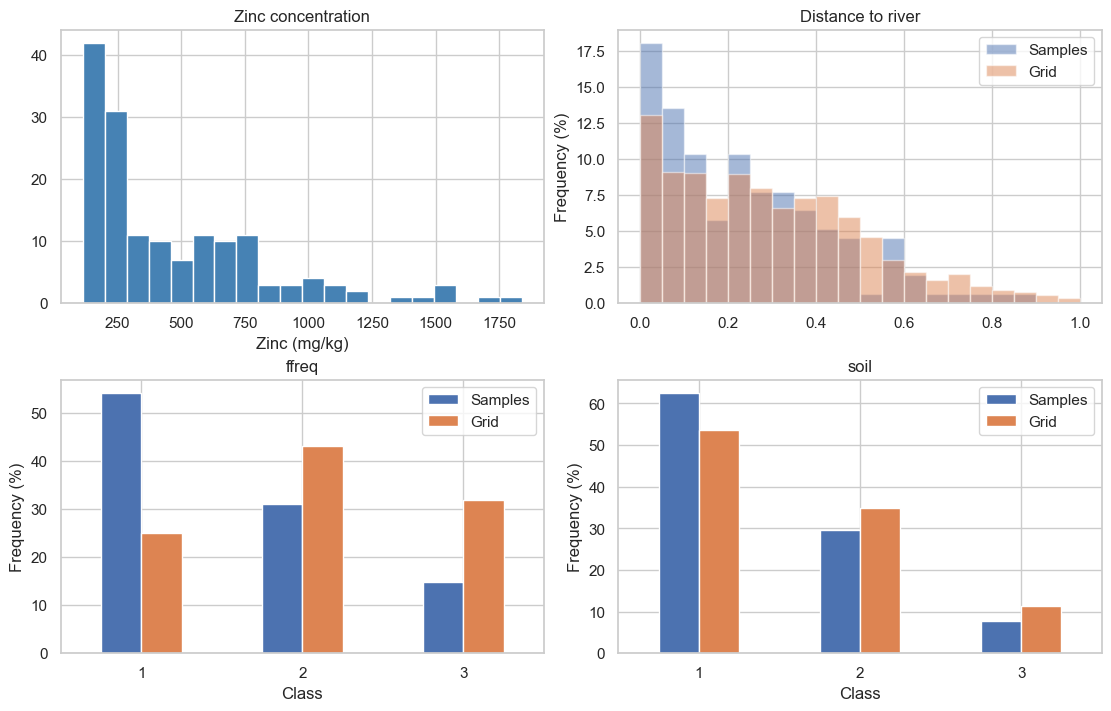

In [5]:
for name, df in [("Observations", meuse), ("Prediction grid", grid)]:
    cols = ["x", "y", "dist", *CAT] + (["zinc"] if name == "Observations" else [])
    print(name, "— missing values:")
    display(df[cols].isna().sum().to_frame("Missing").T)
    assert df[cols].notna().all().all()
    assert not df.duplicated(["x", "y"]).any()
    assert np.isfinite(df[[c for c in cols if c not in CAT]].to_numpy(float)).all()
    assert df.dist.between(0, 1).all()
    assert all(df[col].isin(["1", "2", "3"]).all() for col in CAT)
assert (meuse.zinc > 0).all()

display(meuse[["zinc", "dist"]].describe().T.round(2))

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
axes[0, 0].hist(meuse.zinc, bins=20, color="steelblue")
axes[0, 0].set(xlabel="Zinc (mg/kg)", title="Zinc concentration")
for df, label in [(meuse, "Samples"), (grid, "Grid")]:
    axes[0, 1].hist(df.dist, bins=np.linspace(0, 1, 21), alpha=0.5,
                    weights=np.full(len(df), 100/len(df)), label=label)
axes[0, 1].set(title="Distance to river", ylabel="Frequency (%)")
axes[0, 1].legend()
for ax, col in zip(axes[1], CAT):
    freq = pd.DataFrame({"Samples": meuse[col].value_counts(normalize=True),
                         "Grid": grid[col].value_counts(normalize=True)})
    (100 * freq.fillna(0).sort_index()).plot.bar(ax=ax, rot=0)
    ax.set(title=col, xlabel="Class", ylabel="Frequency (%)")
plt.show()

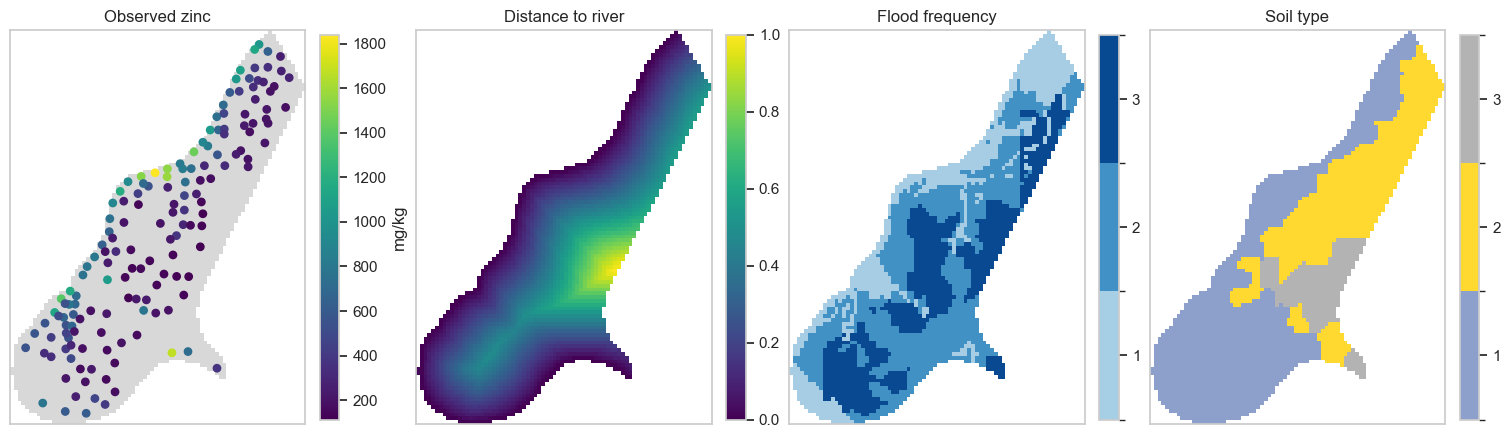

In [6]:
# Represent the prediction grid as 40 m raster cells.
x_grid = np.arange(grid.x.min(), grid.x.max() + 40, 40)
y_grid = np.arange(grid.y.min(), grid.y.max() + 40, 40)
extent = [x_grid[0]-20, x_grid[-1]+20, y_grid[0]-20, y_grid[-1]+20]
ix = np.rint((grid.x.to_numpy() - x_grid[0])/40).astype(int)
iy = np.rint((grid.y.to_numpy() - y_grid[0])/40).astype(int)
assert np.allclose(x_grid[ix], grid.x) and np.allclose(y_grid[iy], grid.y)


def map_grid(ax, values, **kwargs):
    raster = np.full((len(y_grid), len(x_grid)), np.nan)
    raster[iy, ix] = np.asarray(values, dtype=float)
    return ax.imshow(raster, origin="lower", extent=extent, interpolation="nearest", **kwargs)


def map_format(ax, title):
    ax.set(title=title, aspect="equal", xlim=extent[:2], ylim=extent[2:])
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)


def background(ax):
    map_grid(ax, np.ones(len(grid)), cmap="Greys", vmin=0, vmax=4)


fig, axes = plt.subplots(1, 4, figsize=(15, 6), layout="constrained")
background(axes[0])
im = axes[0].scatter(meuse.x, meuse.y, c=meuse.zinc, cmap="viridis", s=28)
fig.colorbar(im, ax=axes[0], label="mg/kg", shrink=0.65)
im = map_grid(axes[1], grid.dist, cmap="viridis", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[1], shrink=0.65)
for ax, col, cmap in zip(axes[2:], CAT, ["Blues", "Set2"]):
    colors = plt.get_cmap(cmap)(np.linspace(0.35, 0.9, 3))
    im = map_grid(ax, grid[col], cmap=ListedColormap(colors),
                  norm=BoundaryNorm([0.5, 1.5, 2.5, 3.5], 3))
    fig.colorbar(im, ax=ax, ticks=[1, 2, 3], shrink=0.65)
for ax, title in zip(axes, ["Observed zinc", "Distance to river", "Flood frequency", "Soil type"]):
    map_format(ax, title)
plt.show()

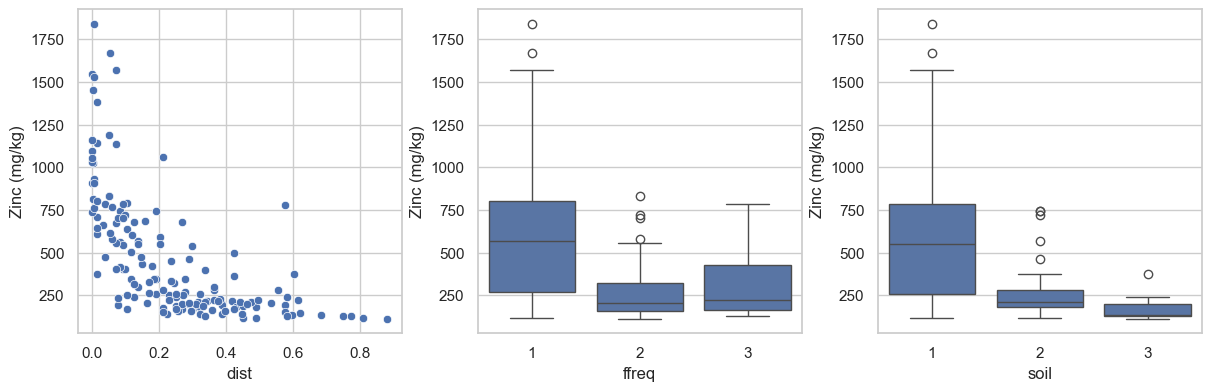

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
sns.scatterplot(data=meuse, x="dist", y="zinc", ax=axes[0])
for ax, col in zip(axes[1:], CAT):
    sns.boxplot(data=meuse, x=col, y="zinc", order=["1", "2", "3"], ax=ax)
for ax in axes:
    ax.set_ylabel("Zinc (mg/kg)")
plt.show()

Zinc is right-skewed, with high concentrations mainly close to the river. High concentrations may strongly influence RMSE. RF does not require a normally distributed target, so let's keep zinc on its original scale.
The environmental predictors may already explain some of the spatial pattern. **Will using more predictors improve the model?**

## 4. Experimental design

| Scenario | Environmental predictors |
|---|---|
| Distance only | `dist` |
| Distance + flood | `dist`, `ffreq` |
| Distance + soil | `dist`, `soil` |
| All environmental predictors | `dist`, `ffreq`, `soil` |

Within each scenario, RF uses the listed predictors, and RFSI adds five neighbouring zinc values and five distances. Both methods use exactly the same folds.

In [8]:
SCENARIOS = {
    "dist": ["dist"],
    "dist + ffreq": ["dist", "ffreq"],
    "dist + soil": ["dist", "soil"],
    "dist + ffreq + soil": ["dist", "ffreq", "soil"],
}

## 4.1. What about adding X and Y coordinates as predictors?

Be careful! Coordinates can act as spatial proxies for unmeasured processes and can improve local prediction. However, they may also introduce location-specific patterns that do not transfer to new geographical regions.

If adding coordinates significantly improves our validation metrics, does it mean that our model has learned more about the environmental processes controlling zinc contamination? **Or has it simply learned where high and low concentrations occur?**

For a controlled comparison, we do not include X and Y as direct predictors in either model.

## 5. Accuracy measures

- **RMSE:** penalizes large errors; in mg kg$^{-1}$. Our main comparison metric.
- **MAE:** typical absolute error, less sensitive to extremes.
- **$R^2$:** improvement over predicting the mean; can be negative.
- **ME:** signed mean error (predicted − observed); close to zero is desirable.
- **CCC:** agreement with the 1:1 line, accounting for correlation and bias.

For CV, calculate metrics from all out-of-fold predictions together, rather than averaging fold-level $R^2$ values.

In [9]:
def regression_metrics(observed, predicted):
    y = np.asarray(observed, dtype=float)
    p = np.asarray(predicted, dtype=float)
    # Retain the sample-moment CCC convention of the original notebook.
    denominator = y.var(ddof=1) + p.var(ddof=1) + (y.mean() - p.mean())**2
    ccc = 2 * np.cov(y, p, ddof=1)[0, 1] / denominator if denominator > 0 else np.nan
    return {"RMSE": mean_squared_error(y, p)**0.5,
            "MAE": mean_absolute_error(y, p),
            "R2": r2_score(y, p),
            "ME": np.mean(p - y), "CCC": ccc}

## 6. Model-building helpers

**Preventing target leakage:** 
This is the critical step for RFSI model.

For an outer training sample, find neighbours only among the outer training samples and remove the sample itself. For an outer validation sample, find neighbours only among the outer training samples. The held-out zinc values must never appear in obs_1, ..., obs_k.

An unsafe workflow would construct nearest-observation predictors once from all 155 samples and then call cross_val_score. A validation sample would then often receive its own zinc or another validation zinc as a predictor. The resulting accuracy could look excellent while being invalid.

In [10]:
def nearest_observation_features(reference, query, exclude_self=False):
    distances = cdist(query[["x", "y"]], reference[["x", "y"]])
    if exclude_self:
        assert np.array_equal(query[["x", "y"]], reference[["x", "y"]])
        np.fill_diagonal(distances, np.inf)
    assert len(reference) >= K_NEIGHBORS + int(exclude_self)
    idx = np.argsort(distances, axis=1, kind="stable")[:, :K_NEIGHBORS]
    d = np.take_along_axis(distances, idx, axis=1)
    z = reference.zinc.to_numpy()[idx]
    names = ([f"obs_{j+1}" for j in range(K_NEIGHBORS)] +
             [f"nn_distance_{j+1}" for j in range(K_NEIGHBORS)])
    return pd.DataFrame(np.column_stack([z, d]), columns=names)


def make_rf_pipeline(columns, seed):
    assert not {"x", "y"}.intersection(columns)
    categorical = [c for c in columns if c in CAT]
    numerical = [c for c in columns if c not in CAT]
    transforms = [("numeric", "passthrough", numerical)]
    if categorical:
        transforms.append(("categorical", OneHotEncoder(handle_unknown="ignore"), categorical))
    return Pipeline([
        ("preprocess", ColumnTransformer(transforms)),
        ("rf", RandomForestRegressor(n_estimators=N_TREES, max_features="sqrt",
                                     min_samples_leaf=2, random_state=seed, n_jobs=1))
    ])


def fit_predict(train, query, seed=RANDOM_STATE):
    # Fit RF and RFSI for each of the four predictor scenarios.
    train, query = train.reset_index(drop=True), query.reset_index(drop=True)
    train_nn = nearest_observation_features(train, train, exclude_self=True)
    query_nn = nearest_observation_features(train, query)
    predictions = {}
    for scenario, cols in SCENARIOS.items():
        for method in METHODS:
            X_train, X_query = train[cols], query[cols]
            if method == "RFSI":
                X_train = pd.concat([X_train, train_nn], axis=1)
                X_query = pd.concat([X_query, query_nn], axis=1)
            model = make_rf_pipeline(X_train.columns, seed)
            model.fit(X_train, train.zinc)
            predictions[scenario, method] = model.predict(X_query)
    return predictions


def score_predictions(data, predictions, validation):
    return pd.DataFrame([
        {"validation": validation, "scenario": s, "method": m,
         **regression_metrics(data.zinc, p)}
        for (s, m), p in predictions.items()
    ])


def run_cv(data, labels, validation, return_folds=False):
    # Store out-of-fold predictions and fold-level metrics
    assert len(labels) == len(data)
    assert len(np.unique(labels)) == N_SPLITS

    oof = {(s, m): np.full(len(data), np.nan)
           for s in SCENARIOS for m in METHODS}
    fold_scores = []

    for i, fold in enumerate(np.unique(labels), start=1):
        train = np.flatnonzero(labels != fold)
        test = np.flatnonzero(labels == fold)
        assert len(train) > K_NEIGHBORS

        pred = fit_predict(data.iloc[train], data.iloc[test],
                           seed=RANDOM_STATE + i)

        for key, values in pred.items():
            oof[key][test] = values

        if return_folds:
            scores = score_predictions(data.iloc[test], pred, validation)
            scores["fold"] = int(fold) + 1
            fold_scores.append(scores)

    assert all(np.isfinite(p).all() for p in oof.values())
    overall = score_predictions(data, oof, validation)

    if return_folds:
        return overall, pd.concat(fold_scores, ignore_index=True), oof

    return overall


## 7. Random 5-fold cross-validation

Randomly divide the observations into five folds. Each fold is used once for validation while the other four are used for training.

The plots below show pooled out-of-fold RMSE, variability between individual folds (fold numbers are identifiers, not an ordered trend), and out-of-fold residuals. Residuals are observed minus predicted, so positive values indicate underestimation and negative values indicate overestimation. The ME metric above uses the opposite sign convention.

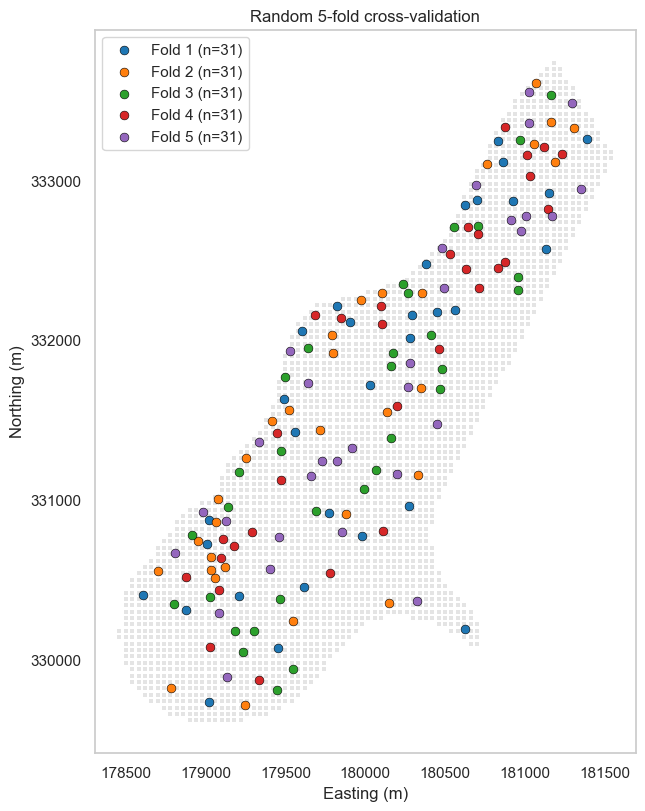

,scenario,method,RMSE,MAE,R2,ME,CCC
0,dist,RF,261.004,183.227,0.491,-5.955,0.697
1,dist,RFSI,228.651,149.510,0.609,1.740,0.734
2,dist + ffreq,RF,232.226,162.545,0.597,-5.739,0.764
3,dist + ffreq,RFSI,218.903,144.131,0.642,1.790,0.754
4,dist + soil,RF,247.971,170.127,0.541,-7.275,0.723
5,dist + soil,RFSI,227.484,149.490,0.613,1.014,0.733
6,dist + ffreq + soil,RF,221.923,156.824,0.632,-2.080,0.779
7,dist + ffreq + soil,RFSI,213.782,141.563,0.659,3.207,0.771


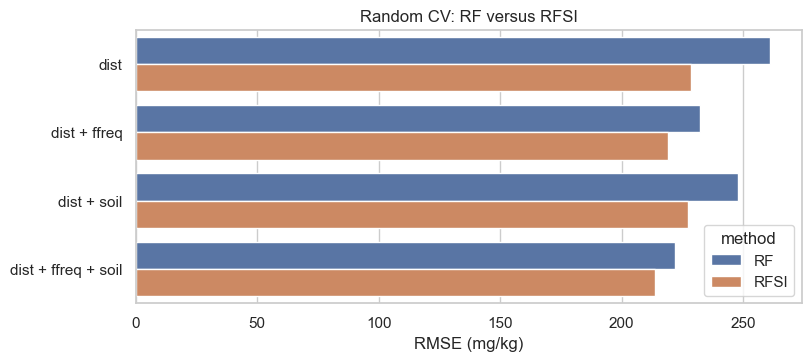

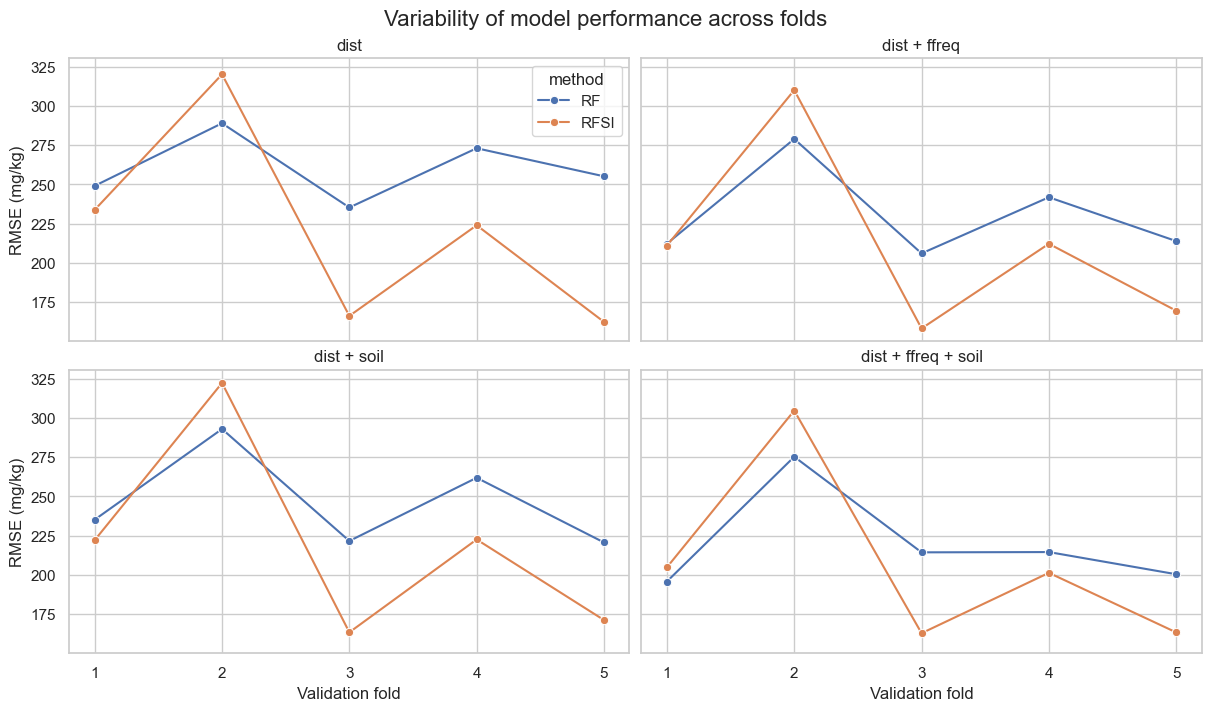

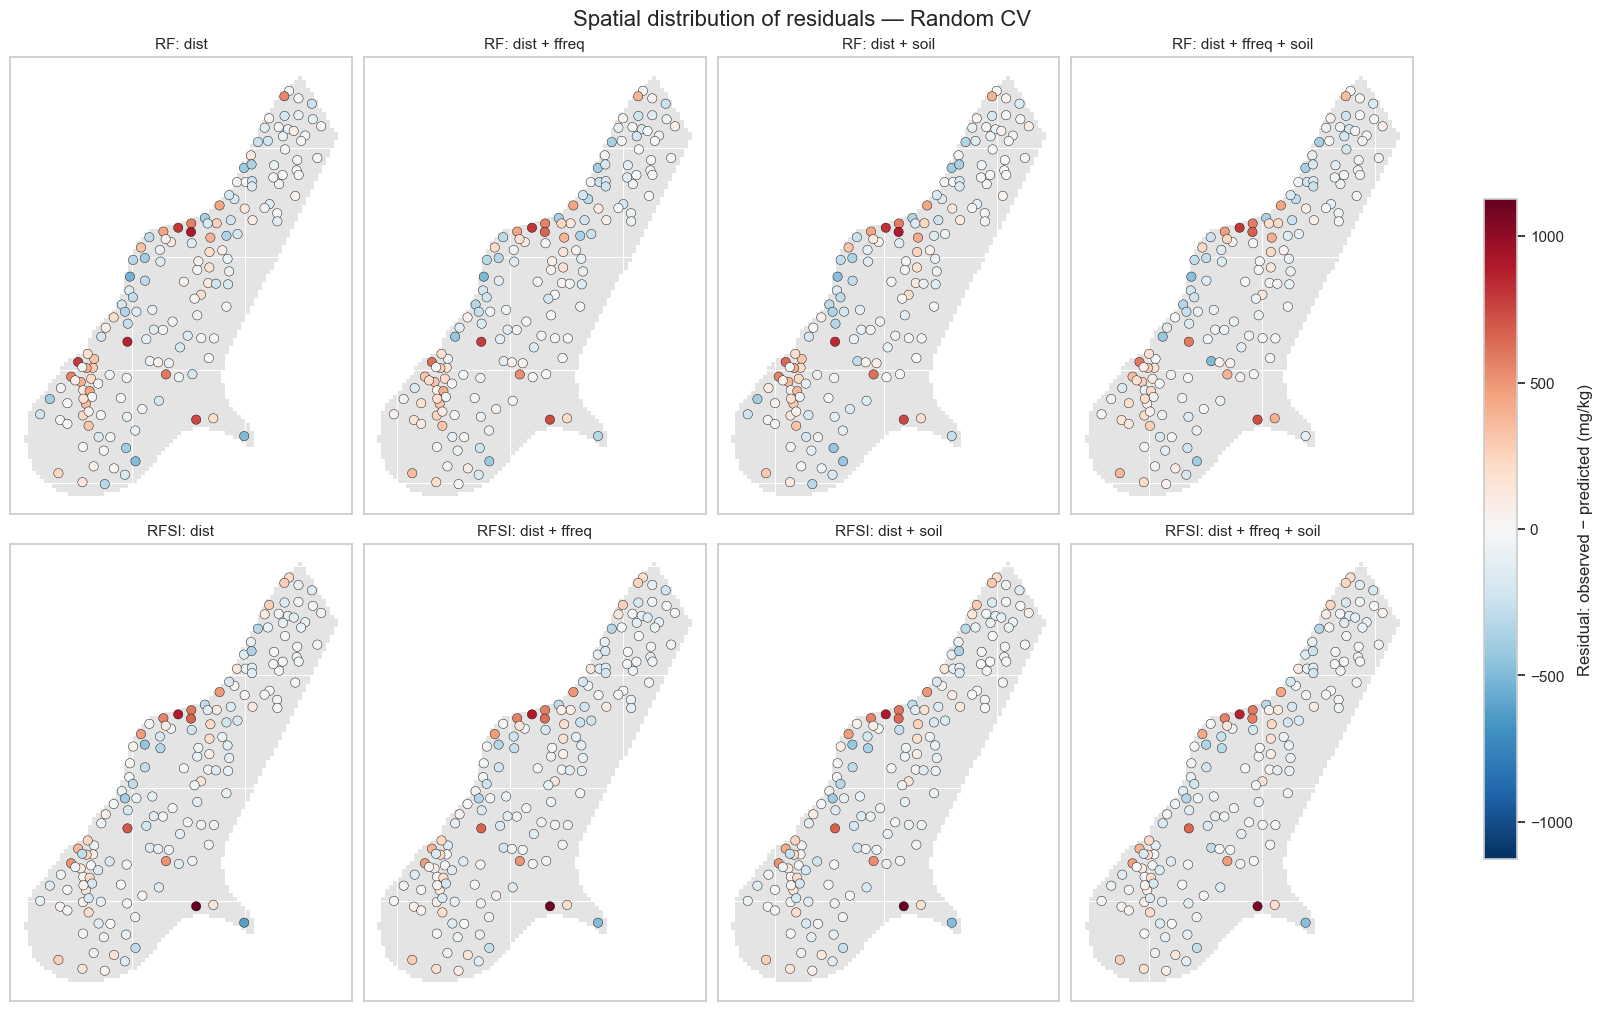

In [11]:
def random_labels(data):
    labels = np.empty(len(data), dtype=int)
    for fold, (_, test) in enumerate(KFold(N_SPLITS, shuffle=True,
                                          random_state=RANDOM_STATE).split(data)):
        labels[test] = fold
    return labels


# ------------------------------------------------------------
# 1. Spatial distribution of random validation folds
# ------------------------------------------------------------

random_id = random_labels(meuse)

fig, ax = plt.subplots(figsize=(7, 8), layout="constrained")

ax.scatter(grid["x"], grid["y"], c="lightgrey",
           marker="s", s=8, linewidths=0, alpha=0.6)

for fold in range(N_SPLITS):
    mask = random_id == fold

    ax.scatter(meuse.loc[mask, "x"], meuse.loc[mask, "y"],
               s=40, color=plt.get_cmap("tab10")(fold),
               edgecolor="black", linewidth=0.4,
               label=f"Fold {fold + 1} (n={mask.sum()})")

ax.set(xlabel="Easting (m)", ylabel="Northing (m)",
       title="Random 5-fold cross-validation")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)
ax.legend()
ax.grid(False)
plt.show()


# ------------------------------------------------------------
# 2. Run cross-validation and calculate accuracy metrics
# ------------------------------------------------------------

random_scores, random_fold_scores, random_oof = run_cv(
    meuse, random_id, "Random CV", return_folds=True
)

display(random_scores.drop(columns="validation").round(3))


# ------------------------------------------------------------
# 3. Overall model performance: RF versus RFSI
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")

sns.barplot(data=random_scores, x="RMSE", y="scenario",
            hue="method", hue_order=METHODS,
            order=list(SCENARIOS), ax=ax)

ax.set(xlabel="RMSE (mg/kg)", ylabel="",
       title="Random CV: RF versus RFSI")

plt.show()


# ------------------------------------------------------------
# 4. Variability of model performance across folds
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 7),
                         sharex=True, sharey=True,
                         layout="constrained")

for ax, scenario in zip(axes.flat, SCENARIOS):

    subset = random_fold_scores[
        random_fold_scores["scenario"] == scenario
    ]

    sns.lineplot(data=subset, x="fold", y="RMSE",
                 hue="method", hue_order=METHODS,
                 marker="o", ax=ax)

    ax.set(title=scenario, xlabel="Validation fold",
           ylabel="RMSE (mg/kg)")
    ax.set_xticks(range(1, N_SPLITS + 1))

    if ax != axes[0, 0]:
        ax.get_legend().remove()

fig.suptitle("Variability of model performance across folds",
             fontsize=16)
plt.show()


# ------------------------------------------------------------
# 5. Spatial distribution of out-of-fold residuals
# ------------------------------------------------------------

# Positive residuals: underestimation
# Negative residuals: overestimation

observed = meuse["zinc"].to_numpy()

random_residuals = {
    key: observed - predicted
    for key, predicted in random_oof.items()
}

# Use the same symmetric colour scale for all maps
vmax = max(np.abs(r).max() for r in random_residuals.values())
vmax = max(vmax, 1e-10)

fig, axes = plt.subplots(
    len(METHODS), len(SCENARIOS),
    figsize=(16, 10),
    sharex=True, sharey=True,
    layout="constrained"
)

for i, method in enumerate(METHODS):
    for j, scenario in enumerate(SCENARIOS):

        ax = axes[i, j]

        # Prediction area
        ax.scatter(grid["x"], grid["y"], c="lightgrey",
                   marker="s", s=8, linewidths=0, alpha=0.6)

        # Validation residuals
        sc = ax.scatter(
            meuse["x"], meuse["y"],
            c=random_residuals[(scenario, method)],
            cmap="RdBu_r",
            vmin=-vmax, vmax=vmax,
            s=45, edgecolor="black", linewidth=0.3
        )

        ax.set_title(f"{method}: {scenario}", fontsize=11)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)

fig.colorbar(
    sc, ax=axes.ravel().tolist(), shrink=0.7,
    label="Residual: observed − predicted (mg/kg)"
)

fig.suptitle("Spatial distribution of residuals — Random CV",
             fontsize=16)

plt.show()

### Interpretation

Does RFSI improve accuracy when only distance to the river is available? Does its advantage remain when flood frequency and soil type are included? Small RMSE differences are not necessarily convincing evidence of model superiority. The following sections investigate how much the results depend on the validation strategy.

## 8. Spatially clustered 5-fold cross-validation

Use K-means to assign nearby observations to the same fold. Validation now asks how well the model predicts in a geographically withheld part of the study area. It can be a much harder task than local interpolation.

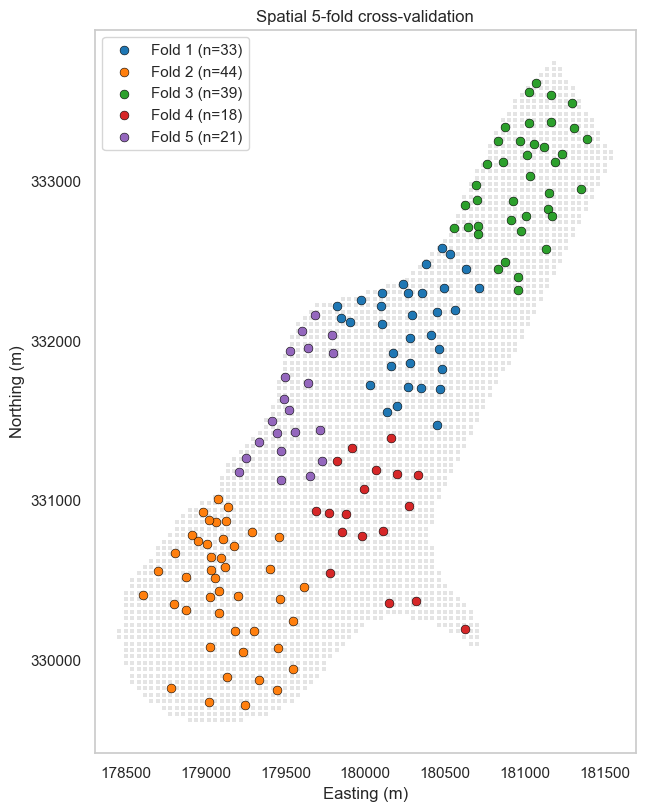

RMSE                   R2           
                           Random CV Spatial CV Random CV Spatial CV
scenario            method                                          
dist                RF       261.004    273.305     0.491      0.442
                    RFSI     228.651    306.337     0.609      0.299
dist + ffreq        RF       232.226    259.607     0.597      0.497
                    RFSI     218.903    313.482     0.642      0.266
dist + ffreq + soil RF       221.923    243.455     0.632      0.557
                    RFSI     213.782    295.661     0.659      0.347
dist + soil         RF       247.971    260.678     0.541      0.492
                    RFSI     227.484    312.488     0.613      0.271

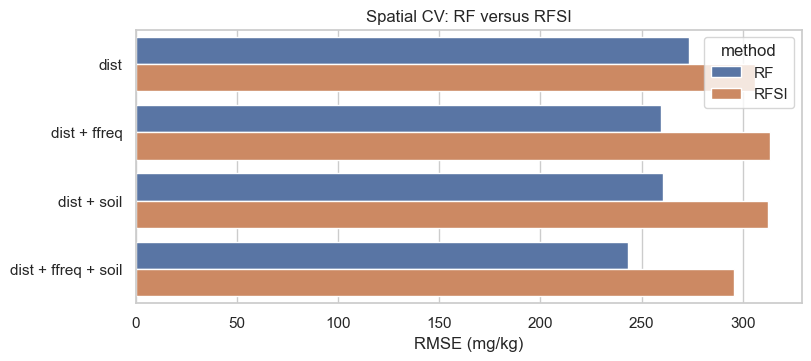

In [12]:
def spatial_labels(data):
    xy = data[["x", "y"]].to_numpy(float)
    # Standardize coordinates before spatial clustering
    xy = (xy - xy.mean(axis=0)) / xy.std(axis=0)
    return KMeans(n_clusters=N_SPLITS, n_init=50,
                  random_state=RANDOM_STATE).fit_predict(xy)


spatial_id = spatial_labels(meuse)

# Map the spatial distribution of validation folds
fig, ax = plt.subplots(figsize=(7, 8), layout="constrained")

ax.scatter(grid["x"], grid["y"], c="lightgrey",
           marker="s", s=8, linewidths=0, alpha=0.6)

for fold in range(N_SPLITS):
    mask = spatial_id == fold
    ax.scatter(meuse.loc[mask, "x"], meuse.loc[mask, "y"],
               s=40, color=plt.get_cmap("tab10")(fold),
               edgecolor="black", linewidth=0.4,
               label=f"Fold {fold + 1} (n={mask.sum()})")

ax.set(xlabel="Easting (m)", ylabel="Northing (m)",
       title="Spatial 5-fold cross-validation")
ax.set_aspect("equal")
ax.ticklabel_format(style="plain", useOffset=False)
ax.legend()
ax.grid(False)
plt.show()


# Run spatial cross-validation
spatial_scores = run_cv(meuse, spatial_id, "Spatial CV")
scores_two = pd.concat([random_scores, spatial_scores], ignore_index=True)

# Compare RMSE and R² between validation strategies
comparison = scores_two.pivot(
    index=["scenario", "method"],
    columns="validation",
    values=["RMSE", "R2"]
).reindex(columns=pd.MultiIndex.from_product(
    [["RMSE", "R2"], CV_ORDER[:2]]
))

display(comparison.round(3))


# Compare RF and RFSI under spatial CV
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")

sns.barplot(data=spatial_scores, x="RMSE", y="scenario",
            hue="method", ax=ax)

ax.set(xlabel="RMSE (mg/kg)", ylabel="",
       title="Spatial CV: RF versus RFSI")

plt.show()

## 9. k-Nearest Neighbour Distance Matching (kNNDM)

[Linnenbrink et al. (2024): k-Nearest Neighbour Distance Matching](https://gmd.copernicus.org/articles/17/5897/2024/)

### What does kNNDM do?

kNNDM constructs validation folds that reproduce the spatial conditions under which the model will be used for prediction.

It searches for a fold configuration that minimizes the Wasserstein distance $W$ between two nearest-neighbour distance distributions:

- Distances from prediction grid cells to their nearest observed sampling locations.
- Distances from held-out validation observations to their nearest training observations during CV.

kNNDM first screens for clustered sampling using a one-sided KS test. In this implementation, if the test does not provide evidence that sample-to-sample distances are systematically shorter than grid-to-sample distances, it uses the existing random CV folds. Otherwise, it searches for spatial fold configurations that minimize the Wasserstein distance between the two distributions.

The compact Python implementation below approximates the geographical algorithm in [CAST::knndm](https://rdrr.io/cran/CAST/src/R/knndm.R). It searches admissible intermediate cluster counts from five to n − 2 for this small dataset. It is not the official R implementation.

**Figure 2.** Schematic illustration of nearest-neighbour distance matching. The green kNNDM curve approximates the black prediction-grid curve. These are illustrative curves, not empirical Meuse results. The small overshoot in the blue sketch is a drawing artifact: a valid cumulative distribution is nondecreasing and stays within [0, 1]. The calculated empirical distributions appear later in the notebook.

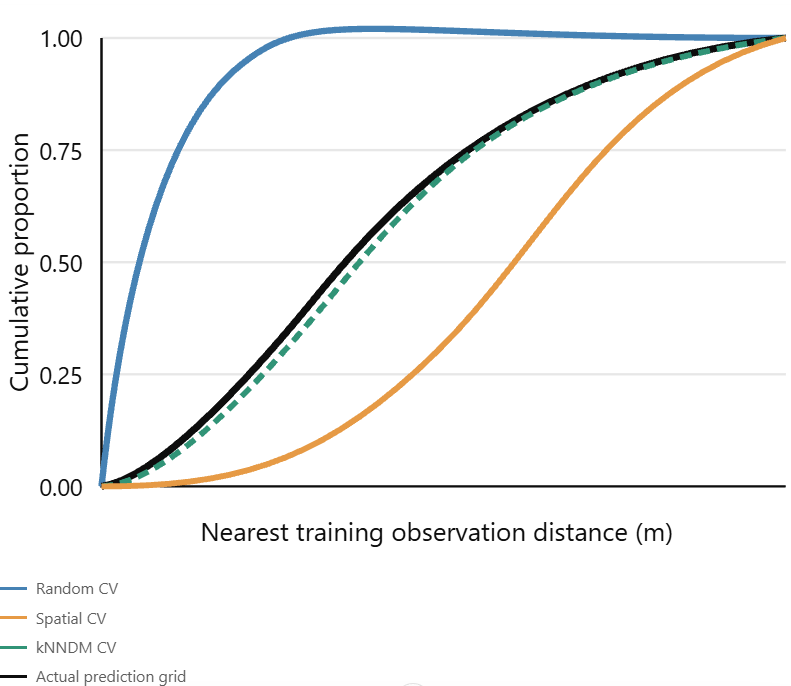

In [13]:
#@title kNNDM illustration { display-mode: "form" }
# Original figure embedded as PNG; no external image file is needed.
from base64 import b64decode
from IPython.display import Image, display

display(Image(data=b64decode(
    "..."
    "KWk4JAAAAABJRU5ErkJggg=="
), format="png", width=791))


In [14]:
def distance_distributions(data, prediction_grid=grid):
    """Pairwise sample distances, LOO distances and grid-to-sample distances."""
    xy = data[["x", "y"]].to_numpy(float)
    D = cdist(xy, xy)
    np.fill_diagonal(D, np.inf)
    target = cdist(prediction_grid[["x", "y"]].to_numpy(float), xy).min(axis=1)
    return D, D.min(axis=1), target


def cv_distances(D, labels):
    """For each observation, find its nearest neighbour in a different fold."""
    same = labels[:, None] == labels[None, :]
    return np.where(same, np.inf, D).min(axis=1)


def merge_clusters(clusters, pc1, k=N_SPLITS):
    """Keep large clusters separate; assign smaller ones cyclically along PC1."""
    ids = np.unique(clusters)
    ordered = sorted(ids, key=lambda c: pc1[clusters == c].mean())
    large = [c for c in ordered if np.sum(clusters == c) >= len(clusters)/k]
    small = [c for c in ordered if c not in large]
    available = list(range(len(large), k))
    if small and not available:
        return None
    mapping = {c: f for f, c in enumerate(large)}
    mapping.update({c: available[i % len(available)] for i, c in enumerate(small)})
    return np.array([mapping[c] for c in clusters])


def make_knndm_labels(data, random_id, alpha=0.05, maxp=0.5):
    D, loo, target = distance_distributions(data)
    ks = ks_2samp(loo, target, alternative="greater", method="asymp")
    info = {"KS statistic": ks.statistic, "KS p-value": ks.pvalue}
    if ks.pvalue >= alpha:
        labels = random_id.copy()
        info.update({"mode": "Random CV fallback", "q": None})
    else:
        xy = data[["x", "y"]].to_numpy(float)
        tree = linkage(xy, method="ward")
        pc1 = PCA(n_components=1).fit_transform(xy).ravel()
        best_W, labels, best_q = np.inf, None, None
        for q in range(N_SPLITS, len(data)-1):
            groups = cut_tree(tree, n_clusters=q).ravel()
            candidate = merge_clusters(groups, pc1)
            if candidate is None:
                continue
            sizes = np.bincount(candidate, minlength=N_SPLITS)
            if sizes.min() == 0 or sizes.max()/len(data) > maxp or len(data)-sizes.max() <= K_NEIGHBORS:
                continue
            W = wasserstein_distance(cv_distances(D, candidate), target)
            if W < best_W:
                best_W, labels, best_q = W, candidate.copy(), q
        if labels is None:
            raise RuntimeError("No admissible kNNDM fold configuration found")
        info.update({"mode": "Hierarchical distance matching", "q": best_q})
    info["W (m)"] = wasserstein_distance(cv_distances(D, labels), target)
    return labels, info

In [15]:
def same_partition(a, b):
    return np.array_equal(a[:, None] == a[None, :], b[:, None] == b[None, :])


def evaluate_knndm(data, labels, random_id, spatial_id, random_scores, spatial_scores):
    # Identical folds do not require another model-fitting experiment.
    for other, scores in [(random_id, random_scores), (spatial_id, spatial_scores)]:
        if same_partition(labels, other):
            return scores.assign(validation="kNNDM CV")
    return run_cv(data, labels, "kNNDM CV")


def show_validation(data, folds, info, withheld=None):
    D, loo, target = distance_distributions(data)
    distances = {"Prediction grid": target,
                 **{name: cv_distances(D, labels) for name, labels in folds.items()}}
    if withheld is not None:
        distances["Withheld observations"] = cdist(withheld[["x", "y"]], data[["x", "y"]]).min(axis=1)
    diagnostics = pd.DataFrame({name: {"Mean (m)": d.mean(),
                    "W (m)": wasserstein_distance(d, target)} for name, d in distances.items()}).T
    print(f"KS statistic = {info['KS statistic']:.4f}; p = {info['KS p-value']:.3g}")
    print(f"kNNDM: {info['mode']}; intermediate clusters: {info['q']}")
    for name in CV_ORDER[:2]:
        print(f"Same partition as {name}: {same_partition(folds[name], folds['kNNDM CV'])}")
    display(diagnostics.round(2))

    # Fold maps and cumulative distance distributions.
    fig, axes = plt.subplots(1, 4, figsize=(15, 5),
                             gridspec_kw={"width_ratios": [1, 1, 1, 1.8]}, layout="constrained")
    for ax, (name, labels) in zip(axes[:3], folds.items()):
        background(ax)
        ax.scatter(data.x, data.y, c=labels, cmap="tab10", vmin=0, vmax=9, s=25)
        map_format(ax, name)
    ax = axes[3]
    for name, d in distances.items():
        x = np.sort(d)
        ax.step(np.r_[0, x], np.r_[0, np.arange(1, len(x)+1)/len(x)], where="post",
                label=name, color="black" if name == "Prediction grid" else None,
                linestyle="--" if name in ["kNNDM CV", "Withheld observations"] else "-")
    ax.set(xlabel="Nearest observation (m)", ylabel="Cumulative proportion", title="Distance matching")
    ax.legend(fontsize=8)
    plt.show()
    return diagnostics


def compare_scores(scores, order):
    # Show all metrics in a compact table, then focus on RMSE differences.
    display(scores.set_index(["validation", "scenario", "method"]).round(3))
    rmse = scores.pivot(index=["scenario", "method"], columns="validation", values="RMSE")
    idx = pd.MultiIndex.from_product([SCENARIOS, METHODS], names=["scenario", "method"])
    rmse = rmse.reindex(index=idx, columns=order)
    delta = rmse.xs("RFSI", level="method") - rmse.xs("RF", level="method")
    print("RFSI minus RF: RMSE (negative values favour RFSI)")
    display(delta.round(2))
    print("Best configuration by RMSE:")
    display(scores.sort_values("RMSE").groupby("validation").head(1)
            .set_index("validation").reindex(order)[["scenario", "method", "RMSE"]].round(2))
    return rmse, delta

KS statistic = 0.0515; p = 0.44
kNNDM: Random CV fallback; intermediate clusters: None
Same partition as Random CV: True
Same partition as Spatial CV: False


,Mean (m),W (m)
Prediction grid,96.13,0.00
Random CV,123.15,32.78
Spatial CV,502.95,406.82
kNNDM CV,123.15,32.78


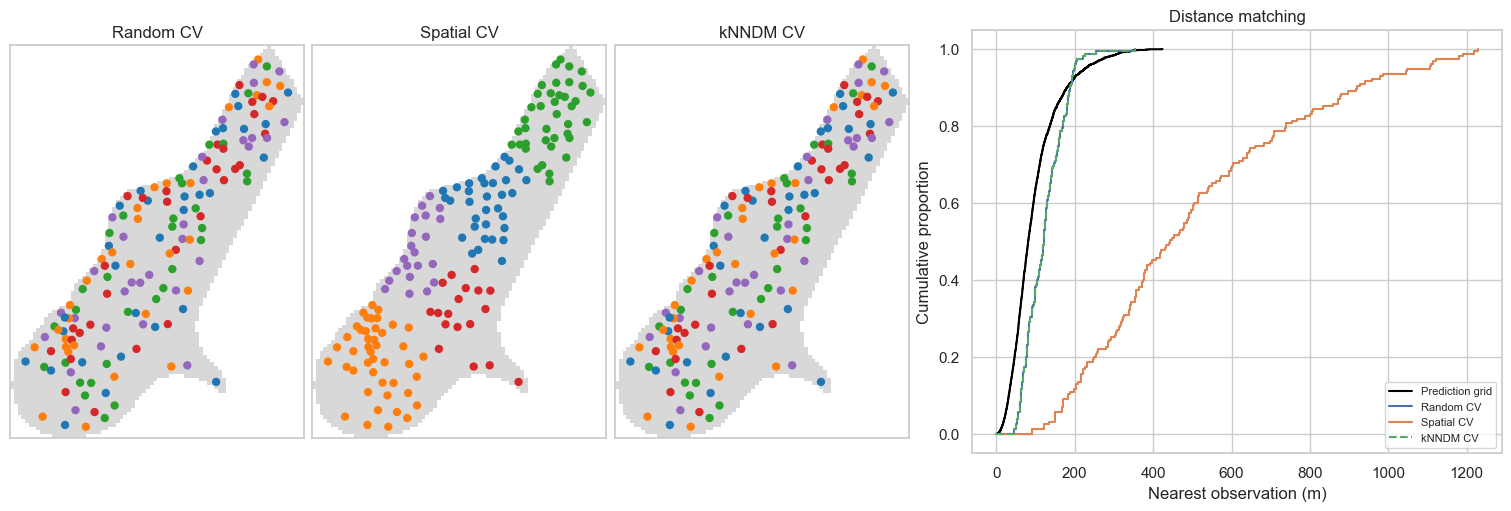

RMSE      MAE     R2       ME    CCC
validation scenario            method                                         
Random CV  dist                RF      261.004  183.227  0.491   -5.955  0.697
                               RFSI    228.651  149.510  0.609    1.740  0.734
           dist + ffreq        RF      232.226  162.545  0.597   -5.739  0.764
                               RFSI    218.903  144.131  0.642    1.790  0.754
           dist + soil         RF      247.971  170.127  0.541   -7.275  0.723
                               RFSI    227.484  149.490  0.613    1.014  0.733
           dist + ffreq + soil RF      221.923  156.824  0.632   -2.080  0.779
                               RFSI    213.782  141.563  0.659    3.207  0.771
Spatial CV dist                RF      273.305  189.147  0.442    8.438  0.685
                               RFSI    306.337  234.533  0.299   97.214  0.495
           dist + ffreq        RF      259.607  192.685  0.497   24.092  0.723
                               RFSI    313.482  241.951  0.266  118.791  0.503
           dist + soil         RF      260.678  182.702  0.492    7.238  0.704
                               RFSI    312.488  243.887  0.271  106.687  0.478
           dist + ffreq + soil RF      243.455  179.082  0.557   24.415  0.745
                               RFSI    295.661  228.904  0.347  108.396  0.562
kNNDM CV   dist                RF      261.004  183.227  0.491   -5.955  0.697
                               RFSI    228.651  149.510  0.609    1.740  0.734
           dist + ffreq        RF      232.226  162.545  0.597   -5.739  0.764
                               RFSI    218.903  144.131  0.642    1.790  0.754
           dist + soil         RF      247.971  170.127  0.541   -7.275  0.723
                               RFSI    227.484  149.490  0.613    1.014  0.733
           dist + ffreq + soil RF      221.923  156.824  0.632   -2.080  0.779
                               RFSI    213.782  141.563  0.659    3.207  0.771

RFSI minus RF: RMSE (negative values favour RFSI)


validation,Random CV,Spatial CV,kNNDM CV
scenario,,,
dist,-32.35,33.03,-32.35
dist + ffreq,-13.32,53.88,-13.32
dist + soil,-20.49,51.81,-20.49
dist + ffreq + soil,-8.14,52.21,-8.14


Best configuration by RMSE:


,scenario,method,RMSE
validation,,,
Random CV,dist + ffreq + soil,RFSI,213.78
Spatial CV,dist + ffreq + soil,RF,243.45
kNNDM CV,dist + ffreq + soil,RFSI,213.78


In [16]:
knndm_id, knndm_info = make_knndm_labels(meuse, random_id)
folds = dict(zip(CV_ORDER, [random_id, spatial_id, knndm_id]))
original_distances = show_validation(meuse, folds, knndm_info)

knndm_scores = evaluate_knndm(meuse, knndm_id, random_id, spatial_id, random_scores, spatial_scores)
original_scores = pd.concat([random_scores, spatial_scores, knndm_scores], ignore_index=True)
original_rmse, original_delta = compare_scores(original_scores, CV_ORDER)

### Interpretation

In the saved Meuse run, kNNDM returned random CV: the distance-based screening test did not detect significant clustering relative to the prediction grid. The two strategies therefore used identical folds and gave identical scores. Spatial CV produced much longer prediction distances.

**Spatial data do not automatically require spatially clustered CV.** The validation design should represent the prediction task.

## 10. Simulation: what if sampling was strongly clustered?

Keep the same prediction grid but retain only eight observations near the centre of each of six geographical clusters (48 of 155 samples). Use the other 107 observations as a withheld test set. Sampling is based on coordinates, not zinc values.

Retained: 48; withheld: 107


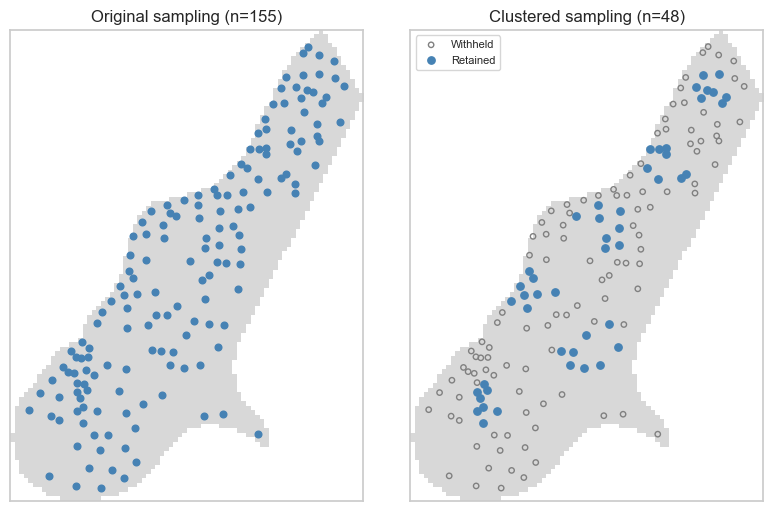

In [17]:
N_SAMPLE_CLUSTERS = 6
POINTS_PER_CLUSTER = 8

xy = meuse[["x", "y"]].to_numpy(float)
km = KMeans(n_clusters=N_SAMPLE_CLUSTERS, n_init=50, random_state=RANDOM_STATE).fit(xy)
retained = []
for c in range(N_SAMPLE_CLUSTERS):
    idx = np.flatnonzero(km.labels_ == c)
    distances = np.linalg.norm(xy[idx] - km.cluster_centers_[c], axis=1)
    retained.extend(idx[np.argsort(distances)[:POINTS_PER_CLUSTER]])
withheld = np.setdiff1d(np.arange(len(meuse)), retained)
sim_data = meuse.iloc[retained].reset_index(drop=True)
sim_holdout = meuse.iloc[withheld].reset_index(drop=True)
print(f"Retained: {len(sim_data)}; withheld: {len(sim_holdout)}")

fig, axes = plt.subplots(1, 2, figsize=(8, 5), layout="constrained")
for ax in axes:
    background(ax)
axes[0].scatter(meuse.x, meuse.y, s=23, color="steelblue")
map_format(axes[0], f"Original sampling (n={len(meuse)})")
axes[1].scatter(sim_holdout.x, sim_holdout.y, s=15, facecolors="none", edgecolors="grey", label="Withheld")
axes[1].scatter(sim_data.x, sim_data.y, s=28, color="steelblue", label="Retained")
map_format(axes[1], f"Clustered sampling (n={len(sim_data)})")
axes[1].legend(fontsize=8)
plt.show()

### Let's repeat the three validation strategies

Does kNNDM now produce different folds? Which CV distance distribution is closest to the actual mapping task?

KS statistic = 0.5913; p = 2.96e-15
kNNDM: Hierarchical distance matching; intermediate clusters: 11
Same partition as Random CV: False
Same partition as Spatial CV: False


,Mean (m),W (m)
Prediction grid,255.87,0.00
Random CV,118.08,142.25
Spatial CV,759.37,503.50
kNNDM CV,291.15,47.07
Withheld observations,244.44,45.42


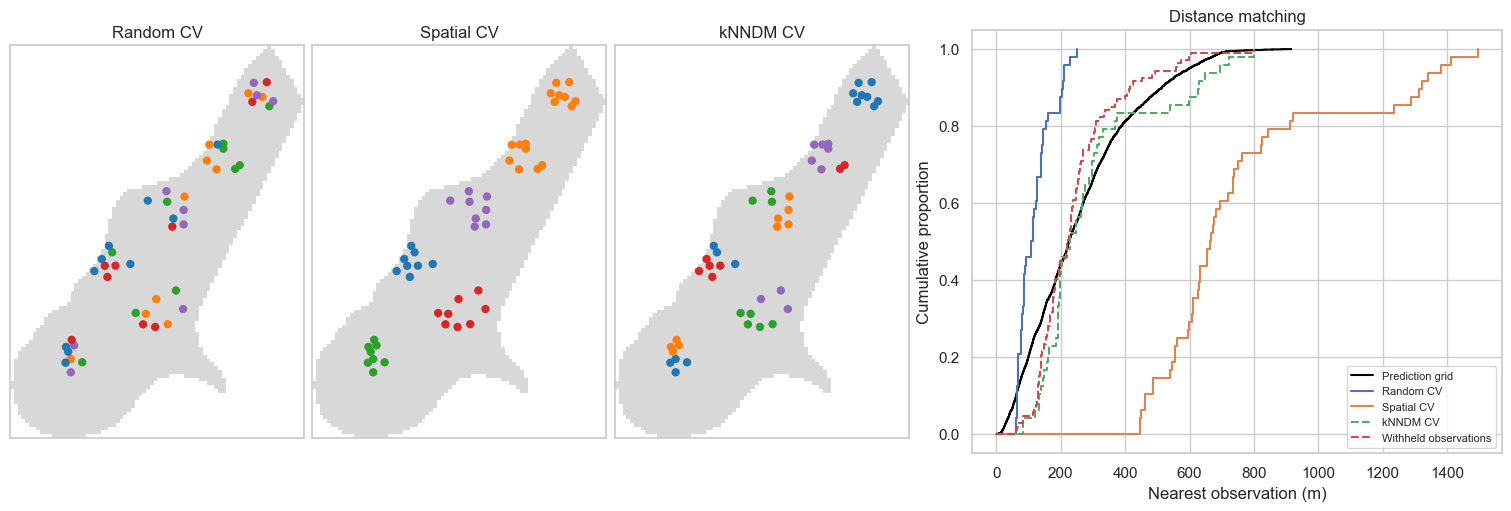

In [18]:
sim_random_id = random_labels(sim_data)
sim_spatial_id = spatial_labels(sim_data)
sim_knndm_id, sim_info = make_knndm_labels(sim_data, sim_random_id)
sim_folds = dict(zip(CV_ORDER, [sim_random_id, sim_spatial_id, sim_knndm_id]))
sim_distances = show_validation(sim_data, sim_folds, sim_info, withheld=sim_holdout)

sim_random = run_cv(sim_data, sim_random_id, "Random CV")
sim_spatial = run_cv(sim_data, sim_spatial_id, "Spatial CV")
sim_knndm = evaluate_knndm(sim_data, sim_knndm_id, sim_random_id, sim_spatial_id,
                          sim_random, sim_spatial)

### External evaluation

Fit each model using all 48 retained observations and predict zinc at the withheld locations. This gives an external benchmark for both accuracy and model ranking. The withheld locations are not a probability sample of the entire grid, so this is not a definitive estimate of map accuracy.

RMSE      MAE     R2      ME  \
validation    scenario            method                                    
Random CV     dist                RF      253.386  190.794  0.159  14.133   
                                  RFSI    278.055  212.263 -0.012  19.314   
              dist + ffreq        RF      229.814  167.061  0.309  17.543   
                                  RFSI    254.470  185.559  0.152  25.215   
              dist + soil         RF      240.835  168.249  0.241   5.019   
                                  RFSI    261.879  197.985  0.102  17.683   
              dist + ffreq + soil RF      208.250  147.441  0.432   7.754   
                                  RFSI    244.813  178.263  0.215  30.174   
Spatial CV    dist                RF      272.398  207.391  0.029  26.269   
                                  RFSI    256.967  182.246  0.135 -27.503   
              dist + ffreq        RF      279.587  219.534 -0.023  75.210   
                                  RFSI    258.590  188.753  0.125  31.330   
              dist + soil         RF      255.928  183.317  0.142  37.289   
                                  RFSI    251.101  186.660  0.174  26.645   
              dist + ffreq + soil RF      254.844  195.989  0.150  71.860   
                                  RFSI    252.193  190.012  0.167  65.349   
kNNDM CV      dist                RF      266.825  202.915  0.068  12.394   
                                  RFSI    249.340  176.853  0.186 -15.682   
              dist + ffreq        RF      242.352  176.541  0.231  17.062   
                                  RFSI    225.806  159.421  0.332  12.698   
              dist + soil         RF      238.356  174.372  0.256  15.005   
                                  RFSI    244.028  180.927  0.220  20.460   
              dist + ffreq + soil RF      209.485  149.724  0.425  15.695   
                                  RFSI    222.689  162.583  0.351  31.977   
Withheld test dist                RF      268.714  204.424  0.542 -11.500   
                                  RFSI    311.199  208.220  0.385 -88.598   
              dist + ffreq        RF      255.727  189.629  0.585 -27.780   
                                  RFSI    293.221  202.091  0.454 -72.171   
              dist + soil         RF      265.161  200.548  0.554 -13.319   
                                  RFSI    292.600  206.059  0.457 -44.719   
              dist + ffreq + soil RF      248.145  174.833  0.609 -43.905   
                                  RFSI    268.360  193.194  0.543 -29.348   

                                            CCC  
validation    scenario            method         
Random CV     dist                RF      0.474  
                                  RFSI    0.146  
              dist + ffreq        RF      0.590  
                                  RFSI    0.312  
              dist + soil         RF      0.535  
                                  RFSI    0.240  
              dist + ffreq + soil RF      0.654  
                                  RFSI    0.392  
Spatial CV    dist                RF      0.421  
                                  RFSI    0.236  
              dist + ffreq        RF      0.461  
                                  RFSI    0.348  
              dist + soil         RF      0.477  
                                  RFSI    0.291  
              dist + ffreq + soil RF      0.517  
                                  RFSI    0.391  
kNNDM CV      dist                RF      0.414  
                                  RFSI    0.307  
              dist + ffreq        RF      0.539  
                                  RFSI    0.481  
              dist + soil         RF      0.522  
                                  RFSI    0.357  
              dist + ffreq + soil RF      0.640  
                                  RFSI    0.521  
Withheld test dist                RF      0.662  
                                  RFSI    0.496  
              dist + ffreq

RFSI minus RF: RMSE (negative values favour RFSI)


validation,Random CV,Spatial CV,kNNDM CV,Withheld test
scenario,,,,
dist,24.67,-15.43,-17.48,42.49
dist + ffreq,24.66,-21.00,-16.55,37.49
dist + soil,21.04,-4.83,5.67,27.44
dist + ffreq + soil,36.56,-2.65,13.20,20.22


Best configuration by RMSE:


,scenario,method,RMSE
validation,,,
Random CV,dist + ffreq + soil,RF,208.25
Spatial CV,dist + soil,RFSI,251.10
kNNDM CV,dist + ffreq + soil,RF,209.49
Withheld test,dist + ffreq + soil,RF,248.15


,W (m),Mean signed RMSE difference,Mean absolute RMSE difference,RF/RFSI ranking agreement (out of 4)
Random CV,142.25,-28.95,28.95,4
Spatial CV,503.50,-15.19,23.75,0
kNNDM CV,47.07,-38.03,38.03,2


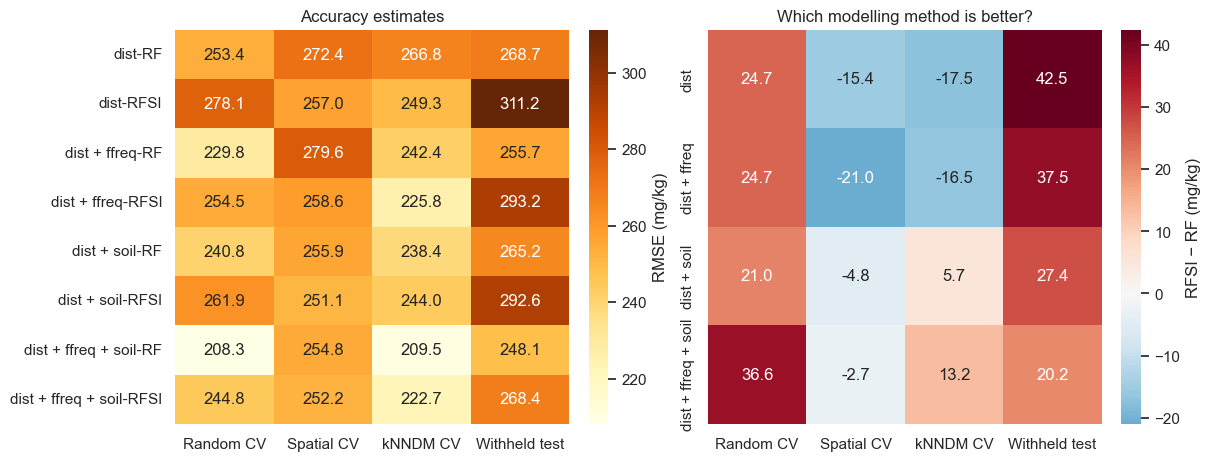

In [19]:
holdout_scores = score_predictions(sim_holdout, fit_predict(sim_data, sim_holdout), "Withheld test")
sim_scores = pd.concat([sim_random, sim_spatial, sim_knndm, holdout_scores], ignore_index=True)
order = CV_ORDER + ["Withheld test"]
sim_rmse, sim_delta = compare_scores(sim_scores, order)

# How close are CV RMSE estimates to the withheld-test RMSE?
gap = sim_rmse[CV_ORDER].subtract(sim_rmse["Withheld test"], axis=0)
summary = pd.DataFrame({
    "W (m)": sim_distances.loc[CV_ORDER, "W (m)"],
    "Mean signed RMSE difference": gap.mean(),
    "Mean absolute RMSE difference": gap.abs().mean(),
    "RF/RFSI ranking agreement (out of 4)":
        np.sign(sim_delta[CV_ORDER]).eq(np.sign(sim_delta["Withheld test"]), axis=0).sum()
})
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
sns.heatmap(sim_rmse, annot=True, fmt=".1f", cmap="YlOrBr", ax=axes[0],
            cbar_kws={"label": "RMSE (mg/kg)"})
sns.heatmap(sim_delta, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[1],
            cbar_kws={"label": "RFSI − RF (mg/kg)"})
axes[0].set(title="Accuracy estimates", xlabel="", ylabel="")
axes[1].set(title="Which modelling method is better?", xlabel="", ylabel="")
plt.show()

### Interpretation of the clustered-sampling experiment

In the saved five-neighbour run:
- kNNDM matched the prediction distances best ($W$ ≈ 47 m), while random CV underestimated and spatial CV overestimated them.
- Spatial CV was closest to the withheld RMSE on average, but favoured RFSI in all four pairwise comparisons.
- Random CV agreed with the withheld RF/RFSI ranking in all four scenarios; kNNDM agreed in two.

The new output tables should be used if results differ. **Matching geographical distances, estimating accuracy and selecting a model are different objectives.** Prediction difficulty also depends on environmental conditions and the full neighbourhood, not just the first neighbour. The experiment is based on one small clustered subsample; CV and the withheld test also use different training sizes and test locations.

## 11. Conclusions

1. Adding neighbouring observations (RFSI) does not necessarily improve RF. The result depends on the available environmental predictors and sampling design.
2. Random CV, spatial CV and kNNDM can estimate different prediction tasks, even for the same model and dataset.
3. kNNDM adapts to the sampling design. In the original dataset it returned random CV; in the clustered simulation it constructed different folds.
4. A good geographical distance match is useful but does not guarantee the best accuracy estimate or model ranking. Small metric differences should not be interpreted as proof of model superiority.

**Main takeaway:** validation is not merely a technical step in the modelling workflow. It is a fundamental methodological decision that determines what we can conclude about our model and how much we can trust its predictions. Design validation from the outset according to the prediction objective and sampling design, not simply because the data are spatial.